# 03 — Baseline Possession (H/A/D) & Feature Pipeline

**Tujuan:** membuat prediksi pertama yang *end-to-end*, dapat direproduksi, dan mematuhi format submission menggunakan `src/features.py` dan `games.py`.

**Bukan model final.** `nearest_team_proxy` hanyalah tim terdekat, bukan ground truth; `SET PIECES` hanya konteks fase, bukan interval dead-ball eksak. Semua skor di notebook ini adalah *heuristic evidence*, bukan probabilitas terkalibrasi.

**Aturan kompetisi:** jangan melatih/tuning dengan 5 menit public ground truth, jangan memperbaiki label pada pertandingan ini secara manual, jangan membagikan file tracking/video asli atau turunannya. Notebook ini tidak membaca ground truth.

Dependensi: `numpy pandas matplotlib kloppy` dan modul lokal `games.py`, `src/features.py`. Dataset tactical ada di `data/tactical/` atau `MTAH_DATA_DIR`.

## 0. Setup dan path (jalankan dari `notebooks/` atau root project)

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "games.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("games.py tidak ditemukan. Notebook harus berada di project/notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import games
from src.features import build_features
N = games.source_frames('tactical')
FPS = games.GAMES[games.GAME]['fps']
HALVES = games.half_video_blocks(games.GAME)
print('Project root:', ROOT)
print('Asset paths:', games.asset_paths())
print('Halves:', HALVES)
print('Frames:', N, 'fps:', FPS)

Project root: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg
Asset paths: {'video': 'C:\\Users\\HP 840\\Documents\\Hizkia ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\data\\tactical\\BAR-ATH_tactical.mp4', 'atd_meta': 'C:\\Users\\HP 840\\Documents\\Hizkia ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\data\\tactical\\BAR-ATH_tactical_atd.xml', 'atd_raw': 'C:\\Users\\HP 840\\Documents\\Hizkia ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\data\\tactical\\BAR-ATH_tactical_atd.txt', 'homography': 'C:\\Users\\HP 840\\Documents\\Hizkia ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\data\\tactical\\BAR-ATH_tactical_homography.csv', 'smart_tagging': 'C:\\Users\\HP 840\\Documents\\Hizkia ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\data\\tactical\\BAR-ATH_tactical_smart_tagging.xml'}
Halves: [(1, 11185, 90651), (2, 110808, 190197)]
Frames: 199319 fps: 25


## 1. Build feature table dari dataset asli

Proses membaca ATD dan Smart Tagging bisa membutuhkan memori/waktu beberapa saat. Modul memverifikasi `frame_id` kloppy yang dimulai dari 1, lalu mengindeks output dengan `frame=0..N-1`. Offset raw `IdFrame` yang berbeda per babak tidak diterapkan dua kali.

In [2]:
bundle = build_features()
f = bundle.frames
print('Features:', f.shape)
print('Slots by team:')
display(bundle.slots.groupby('side').size().rename('slots').to_frame())
print('Top Smart Tag codes:')
display(bundle.events.code_clean.value_counts().head(12).to_frame('instances'))
display(f.head(3))
assert len(f)==N and f.frame.iloc[0]==0 and f.frame.iloc[-1]==N-1
assert f.graded.sum()==158857
print('Ball observed in graded frames:', round(100*f.loc[f.graded,'ball_ok'].mean(),2),'%')

Features: (199319, 25)
Slots by team:


,slots
side,
A,22
H,24


Top Smart Tag codes:


,instances
code_clean,
PLAYERS IN THE BOX,97
BALL IN FINAL THIRD,93
BALL IN THE BOX,72
PROGRESSION,66
DEFENDING IN MIDDLE THIRD,66
SET PIECES,59
CREATING CHANCES,30
DEFENDING IN DEFENSIVE THIRD,30
LONG BALL,29


,frame,half,graded,ball_x,ball_y,ball_ok,ball_missing_run_frames,frames_since_ball_seen,frames_until_ball_seen,home_count,...,nearest_team_proxy,ball_speed2d_mps,centroid_speed_H_mps,centroid_speed_A_mps,active_tag_count,active_h_tags,active_a_tags,set_piece_tag,set_piece_start,set_piece_end
0,0,0,False,NaN,NaN,False,0,NaN,NaN,2,...,?,NaN,NaN,NaN,0,0,0,False,False,False
1,1,0,False,NaN,NaN,False,0,NaN,NaN,2,...,?,NaN,NaN,NaN,0,0,0,False,False,False
2,2,0,False,NaN,NaN,False,0,NaN,NaN,2,...,?,NaN,NaN,NaN,0,0,0,False,False,False


Ball observed in graded frames: 59.31 %


## 2. Fitur yang tersedia dan sanity check

Kolom `distance_margin_a_minus_h_m` positif berarti Barcelona lebih dekat. Tidak berarti Barcelona pasti menguasai bola. `ball_missing_run_frames` adalah total panjang *run* yang bisa diketahui karena pemrosesan offline.

In [3]:
cols = ['half','ball_ok','home_count','away_count','nearest_h_m','nearest_a_m',
        'distance_margin_a_minus_h_m','ball_speed2d_mps','ball_missing_run_frames',
        'centroid_speed_H_mps','centroid_speed_A_mps','active_tag_count',
        'active_h_tags','active_a_tags','set_piece_tag']
display(f.loc[f.graded,cols].describe(include='all').T)
assert not f.loc[~f.graded,'half'].any()
assert f.loc[f.graded,'half'].isin([1,2]).all()
assert np.array_equal(f.frame.to_numpy(), np.arange(N))
print('Bola tidak terdeteksi, graded:', int((f.graded & ~f.ball_ok).sum()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
half,158857.0,NaN,NaN,NaN,1.499758,0.500002,1.0,1.0,1.0,2.0,2.0
ball_ok,158857,2,True,94214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_count,158857.0,NaN,NaN,NaN,10.201471,1.964007,0.0,10.0,11.0,11.0,19.0
away_count,158857.0,NaN,NaN,NaN,10.285949,1.733369,1.0,10.0,11.0,11.0,15.0
nearest_h_m,94030.0,NaN,NaN,NaN,5.323916,5.808748,0.00172,1.40334,3.543022,7.136197,59.244635
nearest_a_m,94214.0,NaN,NaN,NaN,6.123765,6.010788,0.00204,2.104331,4.661775,8.36143,86.904342
distance_margin_a_minus_h_m,94030.0,NaN,NaN,NaN,0.748642,7.759494,-49.505145,-2.565612,0.71753,4.523508,57.137761
ball_speed2d_mps,94065.0,NaN,NaN,NaN,6.676758,5.965039,0.0,2.370307,5.081759,9.5382,109.59788
ball_missing_run_frames,158857.0,NaN,NaN,NaN,509.350114,1141.885702,0.0,0.0,0.0,528.0,5537.0
centroid_speed_H_mps,158108.0,NaN,NaN,NaN,1.735369,9.786136,0.0,0.503574,1.032918,1.825192,1164.326836


Bola tidak terdeteksi, graded: 64643


## 3. Baseline scorer — dua subproblem (Team Control dan Live/Dead)

### Team Control
Bukti kedekatan diperoleh dari jarak masing-masing tim dengan bola (`exp(-distance / scale)`) dan tag tim. Ketika bola tidak terdeteksi, informasi tag dapat tetap menghasilkan bukti lemah. Skor `H/A` disimpan sebagai *evidence* dan tidak pernah disebut probabilitas terkalibrasi.

### Live/Dead
Penanda `SET PIECES` **bukan** label D. Kita memakai sinyal lemah: posisi interval restart dan gerak bola/pemain yang rendah. Ini baseline heuristik; dead-ball detection akan menjadi pekerjaan utama iterasi berikutnya.

Semua angka di bawah adalah **konstanta awal yang eksplisit**, bukan angka yang dioptimalkan dari public GT. Silakan uji sensitivitas pada skenario sintetis atau pertandingan lain yang sah; jangan tuning menggunakan public window.

In [4]:
CONFIG = {
    'distance_scale_m': 2.5,      # hanya skala evidence, bukan radius kontrol resmi
    'tag_weight': 0.14,           # tag saling overlap; gunakan bobot kecil
    'continuity_bonus': 0.015,    # prior lama sangat lemah di tahap emission
    'dead_base': 0.012,
    'dead_setpiece_bonus': 0.06,   # tag phase, bukan label dead
    'dead_edge_bonus': 0.20,       # bukti lokal di sekitar batas tag (hipotesis)
    'dead_stationary_bonus': 0.10,
    'dead_low_motion_bonus': 0.035,
    'min_score': 1e-5,
    'transition_penalty': 1.5,    # penalti log-score ganti state / frame
    'short_run_frames': 8,        # hanya untuk diagnosis, bukan hard deletion
}

def emission_evidence(feat, cfg):
    dh = feat.nearest_h_m.to_numpy(float)
    da = feat.nearest_a_m.to_numpy(float)
    observed = feat.ball_ok.to_numpy(bool)
    hs = np.where(np.isfinite(dh), np.exp(-np.maximum(dh,0)/cfg['distance_scale_m']), 0.)
    aas = np.where(np.isfinite(da), np.exp(-np.maximum(da,0)/cfg['distance_scale_m']), 0.)
    ht = feat.active_h_tags.to_numpy(float)
    at = feat.active_a_tags.to_numpy(float)
    # Saturating instead of summing the many correlated overlapping tags.
    hs += cfg['tag_weight']*(1-np.exp(-ht))
    aas += cfg['tag_weight']*(1-np.exp(-at))
    # weak uniform fallback avoids NaN and zero-probability states
    hs += 0.02
    aas += 0.02

    speed = feat.ball_speed2d_mps.to_numpy(float)
    motion = np.nan_to_num(speed, nan=5.0)
    count = feat.home_count.to_numpy(float)+feat.away_count.to_numpy(float)
    centroid_h = feat.centroid_speed_H_mps.to_numpy(float)
    centroid_a = feat.centroid_speed_A_mps.to_numpy(float)
    cent = np.nanmean(np.vstack([centroid_h,centroid_a]),axis=0)
    cent = np.nan_to_num(cent,nan=2.)

    # Only limited evidence of dead status: tag edges and low motion.
    # This intentionally DOES NOT equate all SET PIECES intervals with dead ball.
    dead = np.full(len(feat), cfg['dead_base'])
    dead += cfg['dead_setpiece_bonus']*feat.set_piece_tag.to_numpy(bool)
    edge = feat.set_piece_start.to_numpy(bool) | feat.set_piece_end.to_numpy(bool)
    # 1s shoulder around tag boundaries. Not asserted to equal true boundaries.
    around = np.zeros(len(feat), dtype=bool)
    for ix in np.flatnonzero(edge):
        around[max(0,ix-FPS):min(len(feat),ix+FPS+1)] = True
    dead += cfg['dead_edge_bonus']*around
    dead += cfg['dead_stationary_bonus']*(observed & np.isfinite(speed) & (motion<0.4))
    dead += cfg['dead_low_motion_bonus']*((cent<0.6)&(count>=16))
    scores = np.maximum(np.column_stack([hs, aas, dead]), cfg['min_score'])
    return scores / scores.sum(axis=1,keepdims=True), around

emissions, around_restart = emission_evidence(f, CONFIG)
print('Evidence shape:', emissions.shape, 'classes H, A, D')
print('First graded frame:', emissions[HALVES[0][1]])
assert np.isfinite(emissions).all() and np.allclose(emissions.sum(axis=1),1)

Evidence shape: (199319, 3) classes H, A, D
First graded frame: [0.08581737 0.60524011 0.30894252]


C:\Users\HP 840\AppData\Local\Temp\ipykernel_16004\1645178070.py:35: RuntimeWarning: Mean of empty slice
  cent = np.nanmean(np.vstack([centroid_h,centroid_a]),axis=0)


## 4. Temporal decoding dengan penalti transisi

Viterbi memproses setiap babak terpisah. Transisi dari `H` ke `A`, `H` ke `D`, dan seterusnya dikenai penalti yang sama dalam baseline ini. Implementasi `O(N×3×3)` pada NumPy/Python; bukan HMM yang sudah dipelajari secara statistik.

**Penting:** implementasi tidak menerapkan minimum durasi keras, sehingga possession sah yang singkat tetap memungkinkan jika evidence cukup kuat.

In [5]:
STATES = np.array(['H','A','D'])

def decode_viterbi(log_evidence, penalty=1.5):
    log_evidence = np.asarray(log_evidence, dtype=float)
    t = len(log_evidence)
    if t == 0:
        return np.array([],dtype='<U1')
    if log_evidence.shape[1] != 3 or not np.isfinite(log_evidence).all():
        raise ValueError('Expected finite (frames, 3) log evidences')
    transition = np.full((3,3), -float(penalty),dtype=float)
    np.fill_diagonal(transition,0.0)
    back = np.zeros((t,3),dtype=np.uint8)
    dp = log_evidence[0].copy()
    for i in range(1,t):
        candidate = dp[:,None]+transition
        back[i] = candidate.argmax(axis=0)
        dp = log_evidence[i]+candidate.max(axis=0)
    result = np.zeros(t,dtype=np.uint8)
    result[-1] = dp.argmax()
    for i in range(t-1,0,-1):
        result[i-1] = back[i,result[i]]
    return STATES[result]

# Synthetic cases for the algorithm (NOT data/labels from the competition):
synthetic=np.array([[.95,.04,.01]]*10+[[.01,.98,.01]]*20+[[.01,.03,.96]]*15)
synthetic_result=decode_viterbi(np.log(synthetic),1.5)
assert (synthetic_result[:10]=='H').all()
assert (synthetic_result[10:30]=='A').all()
assert (synthetic_result[30:]=='D').all()

labels=np.full(N,'X',dtype='<U1')
for h,lo,hi in HALVES:
    part=np.log(np.clip(emissions[lo:hi+1],1e-10,1))
    labels[lo:hi+1]=decode_viterbi(part,CONFIG['transition_penalty'])
assert np.isin(labels,['H','A','D','X']).all()
assert (labels[~f.graded.to_numpy()]=='X').all()
print(pd.Series(labels[f.graded.to_numpy()]).value_counts().to_frame('frames'))

   frames
H   84601
A   59672
D   14584


## 5. Segment diagnostics (bukan evaluasi ground truth)

Metrik di bagian ini **tidak memberi tahu** apakah possession benar. Hanya menghitung karakteristik output seperti jumlah segmen, durasi dan segmentasi berlebihan. Hanya H/A disebut possession; D adalah stoppage.

In [6]:
def summarize_segments(labels, half):
    rows=[]
    for h in (1,2):
        inds=np.flatnonzero(half==h)
        if not len(inds): continue
        lo,hi=int(inds[0]),int(inds[-1])
        vals=labels[lo:hi+1]
        borders=np.r_[0,np.flatnonzero(vals[1:]!=vals[:-1])+1,len(vals)]
        for a,b in zip(borders[:-1],borders[1:]):
            rows.append({'half':h,'start':lo+int(a),'end':lo+int(b)-1,'label':vals[a],
                         'frames':int(b-a),'seconds':float(b-a)/FPS})
    return pd.DataFrame(rows)

segments=summarize_segments(labels,f.half.to_numpy())
display(segments.groupby('label').agg(segments=('frames','size'),median_s=('seconds','median'),
                                      total_s=('seconds','sum'),short_under_8=('frames',lambda x:int((x<8).sum()))).round(2))
display(segments.query("label in ['H','A']").seconds.describe(percentiles=[.1,.25,.5,.75,.9]).to_frame('predicted possession seconds'))
print('Number of state transitions:',len(segments)-2)  # 2 independent halves
print('Note: output is not scored; public GT intentionally not loaded.')

,segments,median_s,total_s,short_under_8
label,,,,
A,560,1.68,2386.88,7
D,154,2.04,583.36,9
H,592,2.52,3384.04,4


,predicted possession seconds
count,1152.000000
mean,5.009479
std,9.807375
min,0.160000
10%,0.480000
25%,0.880000
50%,2.040000
75%,5.680000
90%,11.912000
max,208.960000


Number of state transitions: 1304
Note: output is not scored; public GT intentionally not loaded.


## 6. Plot prediksi dan bukti pada window otomatis

Jendela contoh dipilih **otomatis** berdasarkan interval set-piece pertama yang berada dalam babak evaluasi. Ini diagnostik semantik, bukan label hasil pengamatan manual. Untuk memeriksa interval lain cukup ganti indeks melalui mekanisme generik tanpa membuat koreksi khusus frame pertandingan.

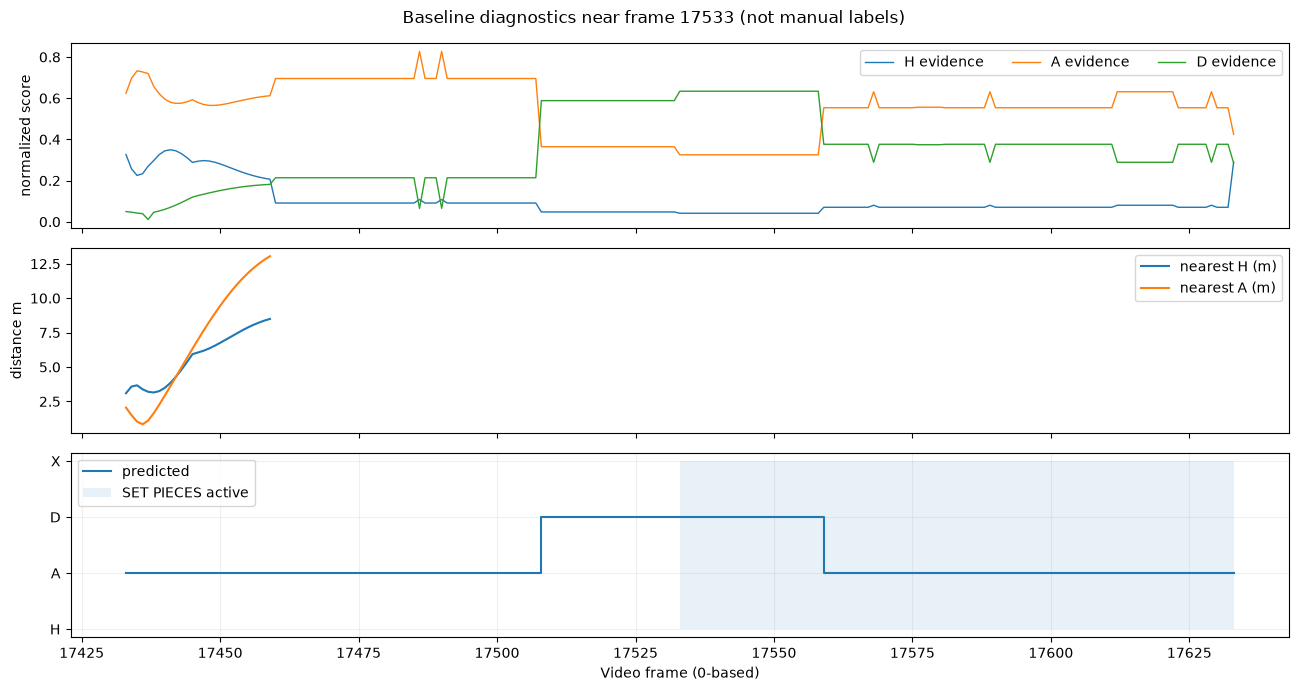

In [7]:
def plot_window(center, radius=4*FPS):
    center=int(center)
    lo=max(0,center-radius);hi=min(N,center+radius+1)
    idx=np.arange(lo,hi)
    fig,axs=plt.subplots(3,1,figsize=(13,7),sharex=True)
    for j,state in enumerate(STATES):
        axs[0].plot(idx,emissions[idx,j],label=f'{state} evidence',lw=1)
    axs[0].legend(ncol=3);axs[0].set_ylabel('normalized score')
    axs[1].plot(idx,f.nearest_h_m.to_numpy()[idx],label='nearest H (m)')
    axs[1].plot(idx,f.nearest_a_m.to_numpy()[idx],label='nearest A (m)')
    axs[1].legend();axs[1].set_ylabel('distance m')
    y=np.array([{'H':0,'A':1,'D':2,'X':3}[q] for q in labels[idx]])
    axs[2].step(idx,y,where='post',label='predicted',lw=1.5)
    axs[2].fill_between(idx,0,3,where=f.set_piece_tag.to_numpy()[idx],alpha=.1,label='SET PIECES active')
    axs[2].set_yticks(range(4),['H','A','D','X']);axs[2].set_xlabel('Video frame (0-based)')
    axs[2].legend();axs[2].grid(alpha=.2)
    fig.suptitle(f'Baseline diagnostics near frame {center} (not manual labels)')
    plt.tight_layout();plt.show()

example_edges=np.flatnonzero(f.set_piece_start.to_numpy() & f.graded.to_numpy())
example_center=int(example_edges[0]) if len(example_edges) else HALVES[0][1]+500
plot_window(example_center)

## 7. Diagnostic: consistency on missing-ball gaps

Cari gap ketika proxy di ujung berbeda dan lihat seberapa sering baseline tetap memprediksi satu tim atau menghasilkan transisi. Klasifikasi ini tidak setara dengan correctness: satu gap panjang bisa memuat beberapa possession sah.

In [8]:
gap_records=[]
for h,lo,hi in HALVES:
    missing=(~f.ball_ok.to_numpy()[lo:hi+1])
    edges=np.diff(np.r_[False,missing,False].astype(np.int8))
    for a,b in zip(np.flatnonzero(edges==1),np.flatnonzero(edges==-1)):
        start=lo+int(a);end=lo+int(b)-1
        before=f.nearest_team_proxy.iloc[start-1] if start>lo else '?'
        after=f.nearest_team_proxy.iloc[end+1] if end<hi else '?'
        gap_records.append({'half':h,'start':start,'end':end,'seconds':(end-start+1)/FPS,
                            'proxy_before':before,'proxy_after':after,
                            'predicted_states':''.join(sorted(set(labels[start:end+1])))})
gaps=pd.DataFrame(gap_records)
print('Missing gaps:',len(gaps))
display(gaps.groupby(['proxy_before','proxy_after']).agg(gaps=('seconds','size'),median_s=('seconds','median')).sort_values('gaps',ascending=False).head(12))
print('Fraction of gaps with predicted changes: ',round((gaps.predicted_states.str.len()>1).mean(),3) if len(gaps) else None)

Missing gaps: 150


gaps  median_s
proxy_before proxy_after                
A            A              49     10.72
H            H              37     10.72
             A              35     10.76
A            H              25      9.28
             ?               1      4.88
?            A               1      0.08
             ?               1     17.20
H            ?               1     37.16

Fraction of gaps with predicted changes:  0.513


## 8. Submission CSV + strict validation

Output disimpan di `evaluation/results/baseline_v1.csv` jika folder tersebut tersedia; jika tidak, dibuat folder `outputs/` lokal. **Jangan commit CSV atau data turunan jika terms melarang publikasi data yang merekonstruksi pertandingan.** Tidak ada video/ATD diekspor.

`evaluation/validate_submission.py` digunakan jika tersedia di repo; selain itu notebook melakukan validasi dasar format dan urutan frame.

In [9]:
from pathlib import Path
OUTPUT_DIR = ROOT/'evaluation'/'results' if (ROOT/'evaluation'/'validate_submission.py').is_file() else ROOT/'outputs'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
OUTPUT_CSV=OUTPUT_DIR/'baseline_v1.csv'
submission=pd.DataFrame({'frame':np.arange(N,dtype=np.int32),'label':labels})
assert submission.shape == (199319,2)
assert submission.columns.tolist()==['frame','label']
assert np.array_equal(submission.frame.to_numpy(),np.arange(N))
assert submission.label.isin(['H','A','D','X']).all()
submission.to_csv(OUTPUT_CSV,index=False)
print('Written:',OUTPUT_CSV, '| bytes:',OUTPUT_CSV.stat().st_size)
validator=ROOT/'evaluation'/'validate_submission.py'
if validator.is_file():
    import subprocess
    proc=subprocess.run([sys.executable,str(validator),str(OUTPUT_CSV)],cwd=ROOT,text=True,capture_output=True)
    print(proc.stdout)
    print(proc.stderr)
    if proc.returncode != 0:
        raise RuntimeError('Official submission validation failed')
else:
    print('Official validation script not found; basic strict checks passed. Run official validator before submission.')

Written: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\evaluation\results\baseline_v1.csv | bytes: 1882093
OK    baseline_v1.csv
      199319 rows, frame 0..199318

      label counts
        H    84601   42.4%
        A    59672   29.9%
        D    14584    7.3%
        X    40462   20.3%

      reports 1152 possessions of mean 5.0 s
      (counted with each X as a gap; the scorer bridges abstentions inside a real
       possession, so its count can be lower than this one)

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.




## 9. Interpretasi dan backlog v1 → v2

1. **Dead-ball detection belum kuat.** `SET PIECES` hanya fase, dan detector di baseline menggunakan indikasi lemah. Perlu analisis restart berbasis event, frame boundaries dan quality gate visual.
2. **Long missing-ball spans belum terselesaikan.** Tagging dan informasi sebelum/sesudah dapat membantu, tetapi tidak membuktikan apa yang terjadi di dalam gap.
3. **Transition timing:** decoder membuat keputusan offline tetapi belum memiliki model duration-aware atau change-point detector.
4. **Bukti bukan confidence terkalibrasi.** H/A/D evidence tidak boleh dilaporkan sebagai peluang benar.
5. **Evaluation:** jangan gunakan public 5 menit untuk memilih parameter. Lakukan tes sintetis dan, bila tersedia, validasi pada pertandingan lain yang sah.
6. **Next:** implementasi `src/team_control.py`, `src/live_dead.py`, `src/temporal_decoder.py`; pindahkan kode notebook ke modul agar CSV dapat diregenerasi dengan satu perintah.

**Security/data use:** jangan unggah tracking/video pertandingan ke cloud model pihak ketiga, jangan hand-label, jangan commit raw match assets. Notebook tidak menggunakan broadcast.